# Yambda 01 · EDA

Same approach as the Last.fm EDA: every question exists to settle a modeling decision.
Yambda adds three signals Last.fm didn't have, so there are new questions too.

| # | Question | Decision it drives |
|---|---|---|
| Q1 | Size, users, time span | sanity, memory |
| Q2 | Organic vs recommended listens | which listens count as *the user's own* discovery |
| Q3 | Skips (`played_ratio`) | what counts as a positive interaction |
| Q4 | Repeats and discovery | target definition (same idea as Last.fm) |
| Q5 | Long tail | vocabulary filter |
| Q6 | Activity over time | train/val/test cut points |
| Q7 | Likes and dislikes | secondary target / extra signal |
| Q8 | Artists (needs mapping file) | does the "familiar artist" finding replicate? |
| Q9 | Sessions | sequential model input |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from musicrec import config
from musicrec.yambda import build_events, load_feedback, load_item_artist, DAY

pd.set_option("display.float_format", "{:,.3f}".format)
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
FIG = config.YAMBDA_FIGURES_DIR
FIG.mkdir(parents=True, exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

df = build_events(min_played_ratio=50)
print(df.shape, f"{df.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df.head()

(46467212, 6) 0.88 GB


,user_id,ts,track_key,is_organic,played_ratio,is_full_listen
0,100,39420,8326270,False,100,True
1,100,39420,1441281,False,100,True
2,100,39625,286361,False,100,True
3,100,40110,732449,False,100,True
4,100,40360,3397170,False,46,False


## Q1 · Size and time span

In [2]:
per_user = df.groupby("user_id").agg(listens=("ts", "size"), tracks=("track_key", "nunique"),
                                     first=("ts", "min"), last=("ts", "max"))
per_user["active_days"] = (per_user["last"] - per_user["first"]) / DAY
pd.Series({
    "listens": len(df),
    "users": len(per_user),
    "tracks": df["track_key"].nunique(),
    "days observed": df["ts"].max() / DAY,
}).to_frame("value")

,value
listens,"46,467,212.000"
users,"9,238.000"
tracks,"877,168.000"
days observed,300.926


In [3]:
per_user.describe(percentiles=[0.1, 0.5, 0.9]).T

,count,mean,std,min,10%,50%,90%,max
listens,"9,238.000","5,030.008","5,520.145",6.000,258.000,"3,023.500","13,043.600","27,617.000"
tracks,"9,238.000","1,436.338","1,292.959",2.000,165.000,"1,087.000","3,188.000","9,843.000"
first,"9,238.000","6,234,868.657","8,060,074.955",0.000,"23,904.000","1,176,180.000","20,360,179.500","24,702,965.000"
last,"9,238.000","25,764,236.779","422,938.783","18,869,525.000","25,284,136.500","25,936,402.500","25,990,822.500","26,000,000.000"
active_days,"9,238.000",226.034,93.894,0.002,61.861,283.151,300.275,300.924


## Q2 · Organic vs recommended

`is_organic = 0` means the service put the track in front of the user (e.g. a personalised radio).
If we evaluated on those, we'd partly be measuring how well we imitate Yandex's own recommender.

organic share of all listens: 51.7%


count   9,238.000
mean        0.540
std         0.310
min         0.000
10%         0.091
50%         0.543
90%         0.974
max         1.000
Name: is_organic, dtype: float64

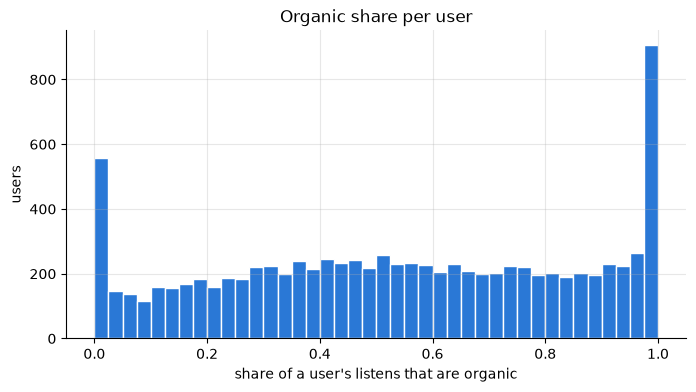

In [4]:
print(f"organic share of all listens: {df['is_organic'].mean():.1%}")
org_by_user = df.groupby("user_id")["is_organic"].mean()

fig, ax = plt.subplots()
ax.hist(org_by_user, bins=40, color=BLUE, edgecolor="white")
ax.set(xlabel="share of a user's listens that are organic", ylabel="users", title="Organic share per user")
save(fig, "y01_organic_share")
org_by_user.describe(percentiles=[0.1, 0.5, 0.9])

## Q3 · Skips

,count,mean,std,min,10%,25%,50%,max
is_organic,,,,,,,,
False,"22,463,555.000",69.577,42.483,0.000,1.000,16.000,100.000,100.000
True,"24,003,657.000",60.150,44.950,0.000,1.000,4.000,99.000,100.000


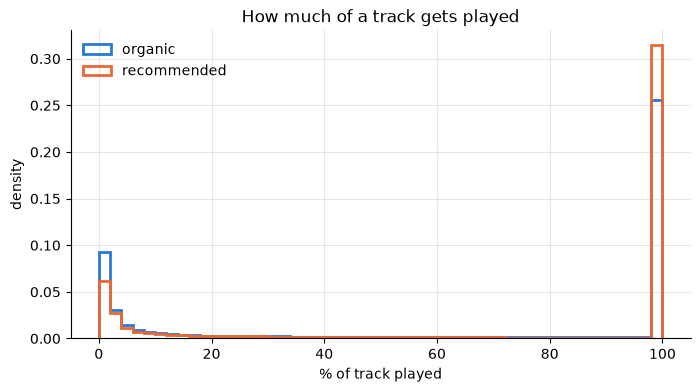

In [5]:
fig, ax = plt.subplots()
for flag, color, label in [(True, BLUE, "organic"), (False, ORANGE, "recommended")]:
    ax.hist(df.loc[df["is_organic"] == flag, "played_ratio"], bins=50, density=True,
            histtype="step", lw=2, color=color, label=label)
ax.set(xlabel="% of track played", ylabel="density", title="How much of a track gets played")
ax.legend(frameon=False)
save(fig, "y01_played_ratio")

df.groupby("is_organic")["played_ratio"].describe(percentiles=[0.1, 0.25, 0.5])

In [6]:
# How sensitive is "full listen" to the threshold?
pd.DataFrame({t: df.groupby("is_organic")["played_ratio"].apply(lambda x: (x >= t).mean())
              for t in [30, 50, 80, 100]}).rename(index={True: "organic", False: "recommended"})

,30,50,80,100
is_organic,,,,
recommended,0.715,0.682,0.648,0.587
organic,0.628,0.588,0.543,0.490


## Q4 · Repeats and discovery

Sorted by user and time, `duplicated(["user_id", "track_key"])` marks every listen of a track the
user has already heard, exactly as for Last.fm.

In [7]:
df["is_repeat"] = df.duplicated(subset=["user_id", "track_key"])
print(f"listens that replay an already-heard track: {df['is_repeat'].mean():.1%}")

first = df[~df["is_repeat"]]
print(f"first-time listens (= discoveries): {len(first):,}")
print(f"  ... of which organic:       {first['is_organic'].mean():.1%}")
print(f"  ... of which full (>=50%):  {first['is_full_listen'].mean():.1%}")

pd.crosstab(df["is_repeat"], df["is_organic"], values=df["is_full_listen"], aggfunc="mean") \
  .rename(index={False: "first listen", True: "repeat"}, columns={False: "recommended", True: "organic"})

listens that replay an already-heard track: 71.4%
first-time listens (= discoveries): 13,268,889
  ... of which organic:       35.0%
  ... of which full (>=50%):  60.2%


is_organic,recommended,organic
is_repeat,,
first listen,0.654,0.506
repeat,0.699,0.608


## Q5 · Long tail (full listens only)

In [8]:
full = df[df["is_full_listen"]]
track_users = full.groupby("track_key")["user_id"].nunique().sort_values(ascending=False)

def top_share(counts, frac):
    k = max(1, int(len(counts) * frac))
    return counts.iloc[:k].sum() / counts.sum()

print(f"tracks: {len(track_users):,} | top 1% hold {top_share(track_users, .01):.1%} of (user, track) pairs")
for k in [1, 2, 5, 10, 20]:
    print(f"tracks with <= {k:>2} listeners: {(track_users <= k).mean():.1%}")

tracks: 631,003 | top 1% hold 37.3% of (user, track) pairs
tracks with <=  1 listeners: 47.1%
tracks with <=  2 listeners: 60.6%
tracks with <=  5 listeners: 75.2%
tracks with <= 10 listeners: 83.3%
tracks with <= 20 listeners: 89.3%


## Q6 · Activity over time → cut points

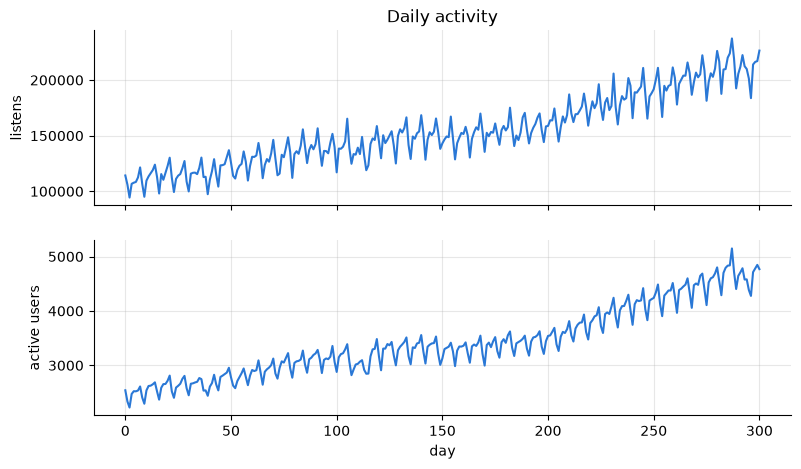

In [9]:
day = (df["ts"] // DAY).rename("day")
daily = df.groupby(day).agg(listens=("user_id", "size"), active_users=("user_id", "nunique"))

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(daily.index, daily["listens"], color=BLUE, lw=1.5); axes[0].set(ylabel="listens", title="Daily activity")
axes[1].plot(daily.index, daily["active_users"], color=BLUE, lw=1.5); axes[1].set(ylabel="active users", xlabel="day")
save(fig, "y01_daily_activity")

In [10]:
# Candidate 14-day evaluation windows. Targets = organic, full, first-time listens.
rows = []
for start in [240, 260, 273, 287]:
    t0, t1 = start * DAY, min(start + 14, 301) * DAY
    before = df[df["ts"] < t0]
    win = df[(df["ts"] >= t0) & (df["ts"] < t1) & df["is_organic"] & df["is_full_listen"]]
    seen = before[["user_id", "track_key"]].drop_duplicates()
    new = (win[["user_id", "track_key"]].drop_duplicates()
              .merge(seen, how="left", indicator=True).query("_merge == 'left_only'"))
    rows.append({"eval window (days)": f"{start}-{t1 // DAY}", "organic new pairs": len(new),
                 "users with >=1": new["user_id"].nunique(),
                 "users active before": before["user_id"].nunique()})
pd.DataFrame(rows)

,eval window (days),organic new pairs,users with >=1,users active before
0,240-254,132690,5663,8386
1,260-274,145821,5995,8733
2,273-287,154703,6286,8975
3,287-301,156078,6787,9238


## Q7 · Likes and dislikes

In [11]:
fb = {k: load_feedback(k) for k in ["likes", "dislikes", "unlikes", "undislikes"]}
pd.DataFrame({k: {"events": len(v), "users": v["uid"].nunique(), "organic share": v["is_organic"].mean()}
              for k, v in fb.items()}).T

,events,users,organic share
likes,"881,456.000","8,283.000",0.570
dislikes,"107,776.000","5,951.000",0.519
unlikes,"312,972.000","6,406.000",0.947
undislikes,"21,033.000","2,911.000",0.890


In [12]:
# Do people like what they discover? Like rate of tracks by how the user first met them.
likes = fb["likes"][["uid", "item_id"]].drop_duplicates().rename(columns={"uid": "user_id", "item_id": "track_key"})
likes["liked"] = True
first_meet = first[["user_id", "track_key", "is_organic", "is_full_listen"]].merge(likes, how="left")
first_meet["liked"] = first_meet["liked"].fillna(False).astype(bool)
first_meet.groupby(["is_organic", "is_full_listen"])["liked"].mean().unstack() \
    .rename(index={False: "found via recommendation", True: "found organically"},
            columns={False: "skipped first time", True: "full first listen"})

is_full_listen,skipped first time,full first listen
is_organic,,
found via recommendation,0.050,0.054
found organically,0.051,0.058


## Q8 · Artists (runs only if `artist_item_mapping.parquet` is in data/raw/yambda/)

In [13]:
item_artist = load_item_artist()
if item_artist is None:
    print("artist mapping not downloaded yet: skipping")
else:
    df["artist"] = df["track_key"].map(item_artist)
    print(f"tracks with an artist: {df['artist'].notna().mean():.1%}")
    df["is_repeat_artist"] = df.duplicated(subset=["user_id", "artist"])
    first = df[~df["is_repeat"]]
    print(f"listens of an already-heard artist: {df['is_repeat_artist'].mean():.1%}")
    print(f"discoveries (new track) by an already-heard artist: {first['is_repeat_artist'].mean():.1%}")
    print(f"  organic discoveries only: {first.loc[first['is_organic'], 'is_repeat_artist'].mean():.1%}")

tracks with an artist: 100.0%
listens of an already-heard artist: 87.6%
discoveries (new track) by an already-heard artist: 56.7%
  organic discoveries only: 58.5%


## Q9 · Sessions (30-minute gap)

In [14]:
gap = df["ts"].diff()
new_user = df["user_id"].ne(df["user_id"].shift())
df["session_id"] = (new_user | (gap > 30 * 60)).cumsum()
session_len = df.groupby("session_id").size()
print(f"sessions: {len(session_len):,}")
session_len.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])

sessions: 2,452,609


count   2,452,609.000
mean           18.946
std            31.271
min             1.000
25%             4.000
50%            10.000
75%            23.000
90%            44.000
99%           132.000
max         7,328.000
dtype: float64

## Decisions (we fill this in together)

| Decision | Choice | Evidence |
|---|---|---|
| Positive interaction (training signal) | | Q3 |
| Eval target | | Q2, Q4, Q7 |
| "Already heard" | any listen in train, skips included | — |
| Minimum listeners per track | | Q5 + threshold table in 02 |
| Cut points | | Q6 |
| Session gap | 30 min | Q9 |